<a href="https://colab.research.google.com/github/yuhui-0611/Unstructured-Data-Analysis/blob/main/UDA_Image_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 목적

- RGB, HSV, LAB, OKLCH는 각각 독립적으로 색상 군집화가 가능하지만, 색공간에 따라 색상 표현과 특징 간 거리가 달라지므로 각 색공간에 K-means를 개별적으로 적용하여 군집화 성능을 비교

In [ ]:
# 데이터 압축 해제 & OKLab 변환용 라이브러리 설치
!unzip -q product_images.zip
!pip install -q colour-science

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.3/59.3 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 95.4 MB/s eta 0:00:00


In [ ]:
import cv2, colour
import numpy as np
import pandas as pd

# 데이터 불러오기
df = pd.read_csv('product_images/labels.csv')
image_files = df['image_path'].tolist()
true_labels = df['color'].tolist()

# 데이터 확인
print(f"총 {len(df)}개 이미지")
df['color'].value_counts()

총 21개 이미지


,count
color,
black,8
beige,7
sora,6


In [ ]:
def to_oklch(bgr):
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    oklab = colour.convert(rgb / 255.0, 'sRGB', 'Oklab')  # RGB를 OKLab로 변환
    L, a, b = oklab[..., 0], oklab[..., 1], oklab[..., 2]
    C = np.sqrt(a**2 + b**2)                 # Chroma
    H = np.degrees(np.arctan2(b, a)) % 360   # Hue
    return np.dstack([L, C, H])

- RGB 이미지를 OKLab 색공간으로 변환한 후 밝기(L), 채도(C), 색상각(H)을 계산하여 OKLCH 색공간으로 변환하는 함수 정의
  - OKLCH는 RGB 값을 변환해서 얻을 수 있는 색공간이지만, RGB에 종속된 색공간은 아님

In [ ]:
images = {'RGB': [], 'HSV': [], 'LAB': [], 'OKLCH': []}
masks = []

for p in image_files:
    bgra = cv2.imread(p, cv2.IMREAD_UNCHANGED)
    bgr = bgra[:, :, :3]
    masks.append(bgra[:, :, 3] > 0)

    images['RGB'].append(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    images['HSV'].append(cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV))
    images['LAB'].append(cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB))
    images['OKLCH'].append(to_oklch(bgr))

print(f"{len(image_files)}개 이미지 × {len(images)}개 색공간 변환 완료")

21개 이미지 × 4개 색공간 변환 완료


- 각 이미지를 RGB, HSV, LAB, OKLCH의 4가지 색공간으로 변환하고, 알파 채널을 이용해 배경을 제외할 마스크를 생성

< key function >
- colour.convert(rgb / 255.0, 'sRGB', 'Oklab'):	RGB 값을 0~1 범위로 변환한 뒤 OKLab 색공간으로 변환
- np.dstack([L, C, H]):	L, C, H 채널을 하나의 이미지 배열로 결합
- cv2.imread(p, cv2.IMREAD_UNCHANGED):	알파 채널을 포함하여 이미지 원본 그대로 불러오기(B, G, R, A)
- cv2.cvtColor(img, code):	이미지의 색공간 변환(OpenCV는 BGR 순서 사용)

In [ ]:
def color_histogram(img, mask, ch_ranges):
    feature = []
    for ch in range(3):
        hist, _ = np.histogram(img[:, :, ch][mask], bins=10, range=ch_ranges[ch])
        feature.extend(hist / hist.sum())
    return feature

- 이미지의 각 색상 채널을 10개 구간으로 나누어 히스토그램을 계산하고, 픽셀 수를 비율로 정규화하여 총 30차원의 특징 벡터를 추출

In [ ]:
ranges = {'RGB':   [(0,255), (0,255), (0,255)],
          'HSV':   [(0,179), (0,255), (0,255)],
          'LAB':   [(0,255), (0,255), (0,255)],
          'OKLCH': [(0,1), (0,0.33), (0,360)]}

features = {}
for space in images:
    X = []
    for img, m in zip(images[space], masks):
        X.append(color_histogram(img, m, ranges[space]))
    features[space] = np.array(X)

print({space: X.shape for space, X in features.items()})

{'RGB': (21, 30), 'HSV': (21, 30), 'LAB': (21, 30), 'OKLCH': (21, 30)}


- RGB, HSV, LAB, OKLCH의 각 색공간에서 의류 영역의 색상 히스토그램을 추출하고, 이미지별 30차원 특징 벡터를 생성

< key function >
- np.histogram(x, bins=10, range=(min, max)): 색상 채널의 값들을 10개 구간으로 나누어 각 구간의 빈도 계산
- hist / hist.sum():	히스토그램의 빈도를 전체 합으로 나누어 비율로 정규화
- feature.extend(...):	각 채널의 히스토그램 값 10개를 하나의 리스트에 추가 (3개 채널 → 30개 값)
- KMeans(n_clusters=k, n_init=10, random_state=42): 군집 개수 k를 지정하여 K-means 모델 생성
- fit_predict(X):	K-means 모델을 학습하고 각 이미지의 군집 번호 반환

In [ ]:
from sklearn.cluster import KMeans

k = 3  # 컬러 옵션 수
labels = {}
for space, X in features.items():
    labels[space] = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)

# 클러스터 결과 확인 (행: 각 이미지의 정답 색상)
pd.DataFrame(labels, index=true_labels)

,RGB,HSV,LAB,OKLCH
sora,0,2,0,1
black,1,1,1,2
sora,0,2,0,1
sora,0,2,0,1
black,1,1,1,2
black,1,1,2,2
black,1,1,1,2
beige,2,0,0,0
black,1,1,1,2
beige,2,0,0,0


- 각 색공간에서 추출한 특징 벡터에 K-means 군집화를 적용하여 이미지를 3개 클러스터로 분류하고, 색공간별 군집 결과를 비교

In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.metrics import accuracy_score, confusion_matrix
from scipy.optimize import linear_sum_assignment
import matplotlib.pyplot as plt
import seaborn as sns

def match_clusters(true, pred):
    ct = pd.crosstab(pd.Series(true), pd.Series(pred))
    rows, cols = linear_sum_assignment(-ct.values)
    mapping = {ct.columns[c]: ct.index[r] for r, c in zip(rows, cols)}
    return [mapping.get(p, 'unmatched') for p in pred]

- K-means의 군집 번호와 실제 색상 label 간의 일치도가 최대가 되도록 군집 번호를 실제 색상에 매칭하는 함수 정의

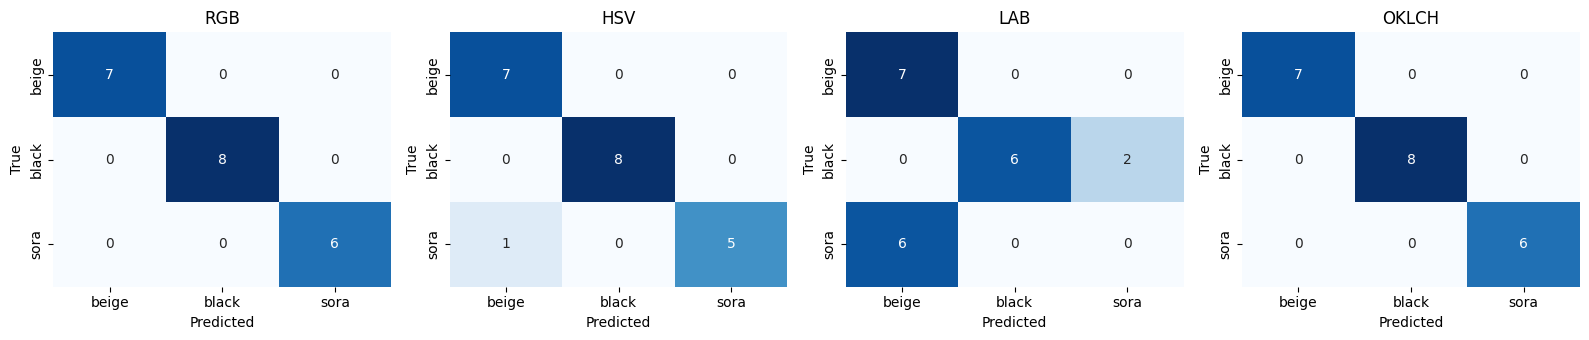

,ARI,NMI,Accuracy
Color space,,,
RGB,1.000,1.000,1.000
HSV,0.866,0.874,0.952
LAB,0.464,0.674,0.619
OKLCH,1.000,1.000,1.000


In [ ]:
colors = sorted(set(true_labels))
results = []

fig, axes = plt.subplots(1, len(labels), figsize=(4*len(labels), 3.5))

for ax, (space, pred) in zip(axes, labels.items()):
    pred_colors = match_clusters(true_labels, pred)

    results.append({
        'Color space': space,
        'ARI': adjusted_rand_score(true_labels, pred),
        'NMI': normalized_mutual_info_score(true_labels, pred),
        'Accuracy': accuracy_score(true_labels, pred_colors)
    })

    cm = confusion_matrix(true_labels, pred_colors, labels=colors)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=colors, yticklabels=colors, ax=ax)

    ax.set(title=space, xlabel='Predicted', ylabel='True')

plt.tight_layout()
plt.show()

pd.DataFrame(results).set_index('Color space').round(3)

- 각 색공간의 K-means 군집화 결과를 실제 색상 label과 비교하여 ARI, NMI, Accuracy를 계산하고, Confusion Matrix를 시각화

< 평가 지표 >

**1. ARI (Adjusted Rand Index)**
- 실제 정답과 군집화 결과가 얼마나 비슷하게 그룹화되었는지 평가하는 지표
  - 1 → 실제 정답과 완벽하게 일치
  - 0 부근 → 무작위 군집화 수준
  - 음수 → 무작위 군집화보다 낮은 일치도
  > 우연에 의한 일치를 보정

**2. NMI (Normalized Mutual Information)**
- 군집화 결과가 실제 색상에 대한 정보를 얼마나 잘 담고 있는지 평가하는 지표
  - 1 → 실제 색상과 군집이 완벽하게 대응
  - 0 → 실제 색상과 군집 사이에 공유 정보가 없음

**3. Accuracy (정확도)**
- 전체 이미지 중 실제 색상을 올바르게 분류한 이미지의 비율

In [ ]:
def show_clusters(space):
    pred = labels[space]
    n_rows, n_cols = pred.max() + 1, np.bincount(pred).max()
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2*n_cols, 2*n_rows), squeeze=False)
    fig.suptitle(f'{space} Clustering', fontsize=16)

    for ax in axes.flat:
        ax.axis('off')

    for c in range(n_rows):
        for j, idx in enumerate(np.where(pred == c)[0]):
            img = images['RGB'][idx].copy()
            img[~masks[idx]] = 255
            axes[c, j].imshow(img)
            axes[c, j].set_title(f'True: {true_labels[idx]}\nPred: {c}', fontsize=8)

    plt.tight_layout()
    plt.show()

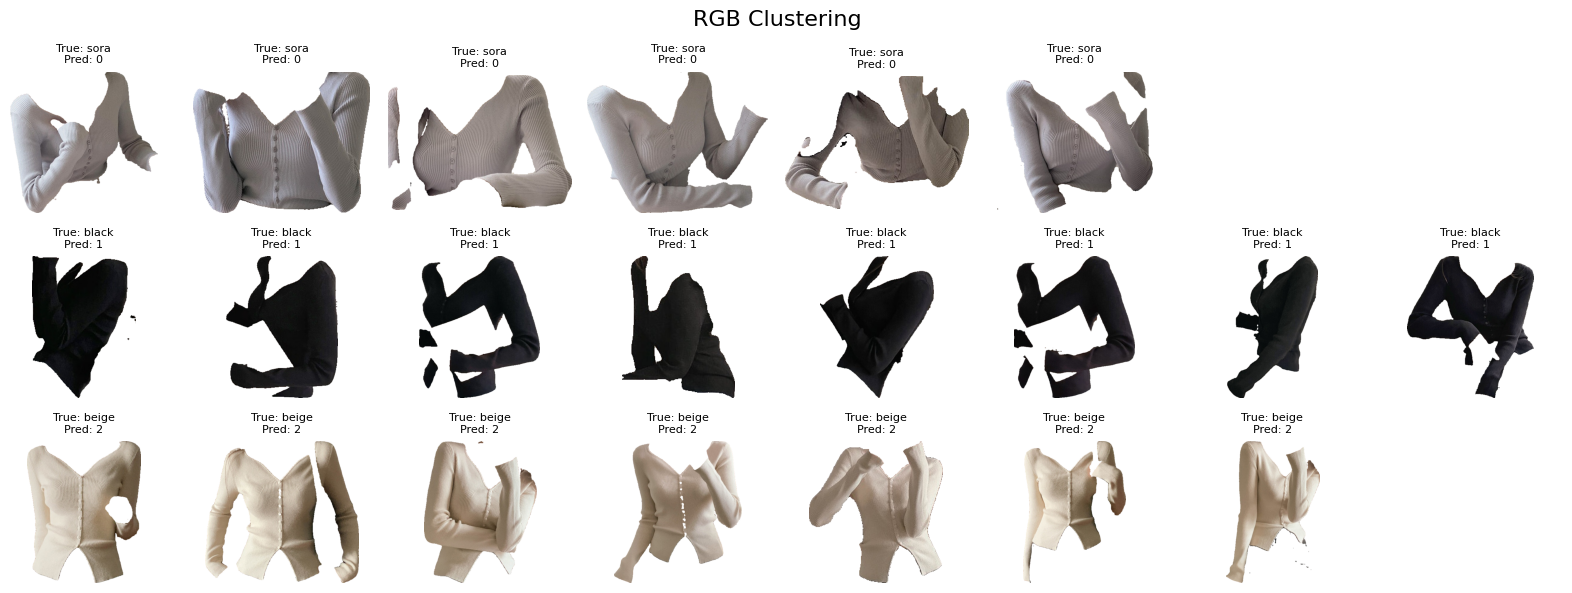

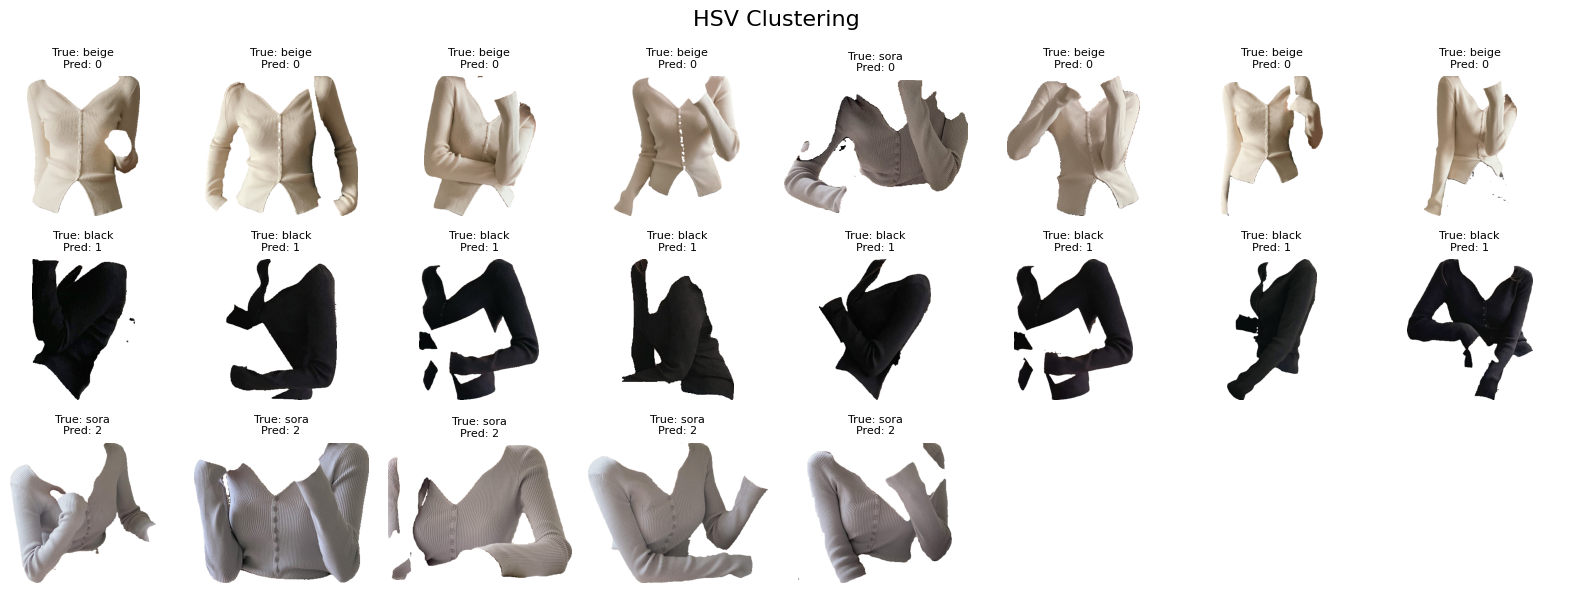

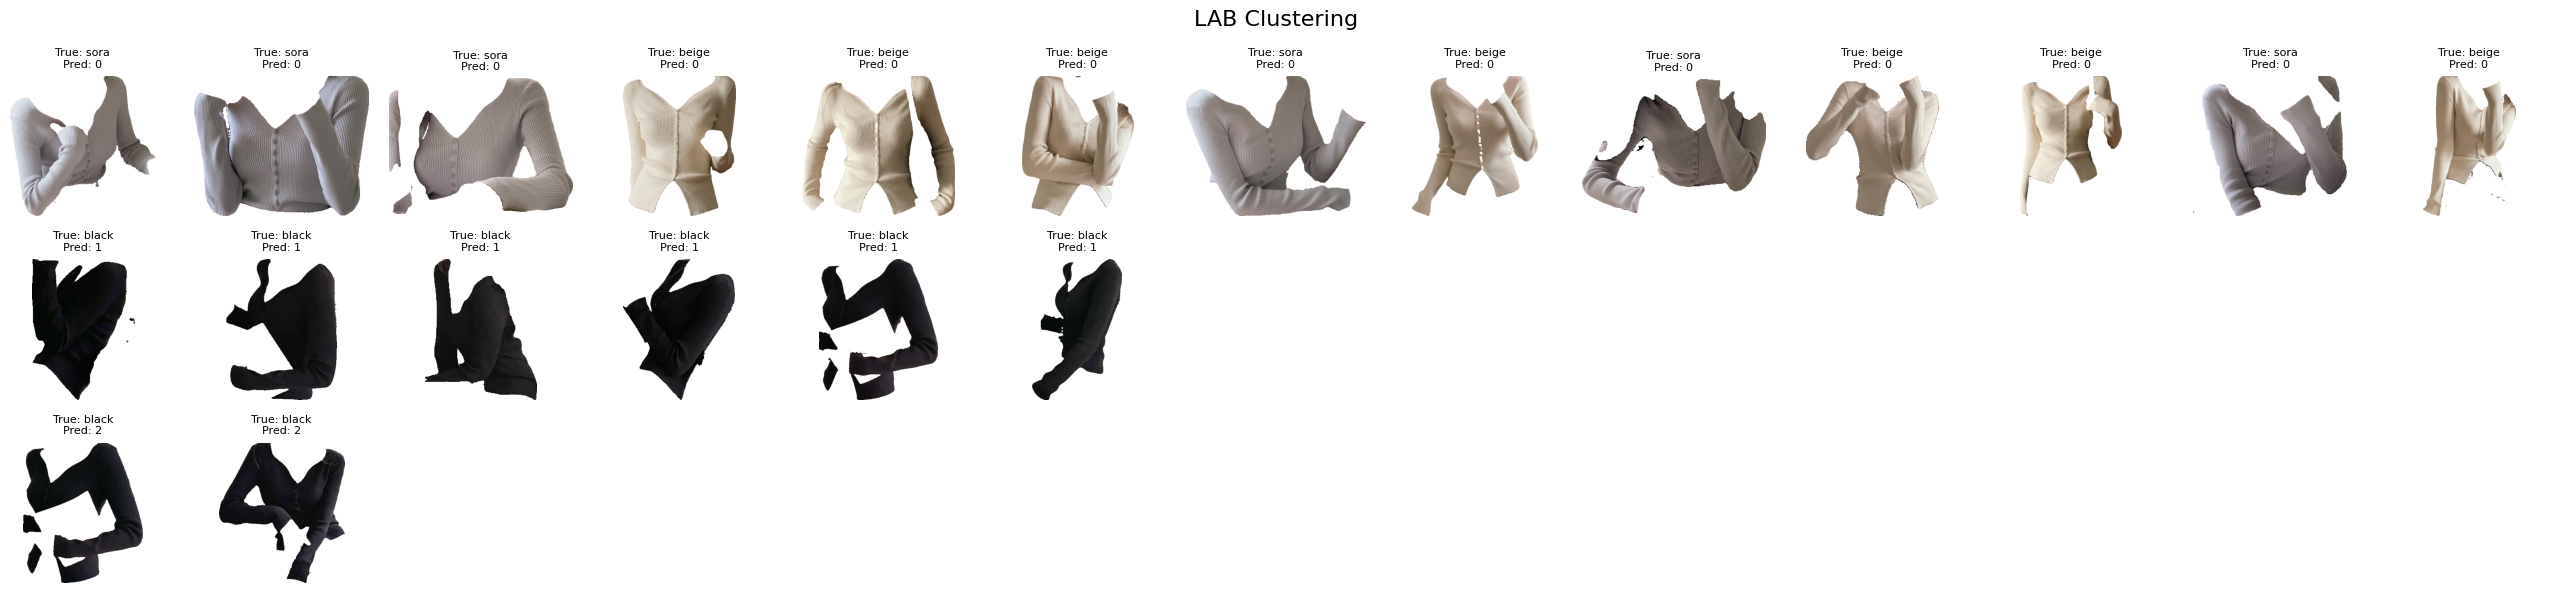

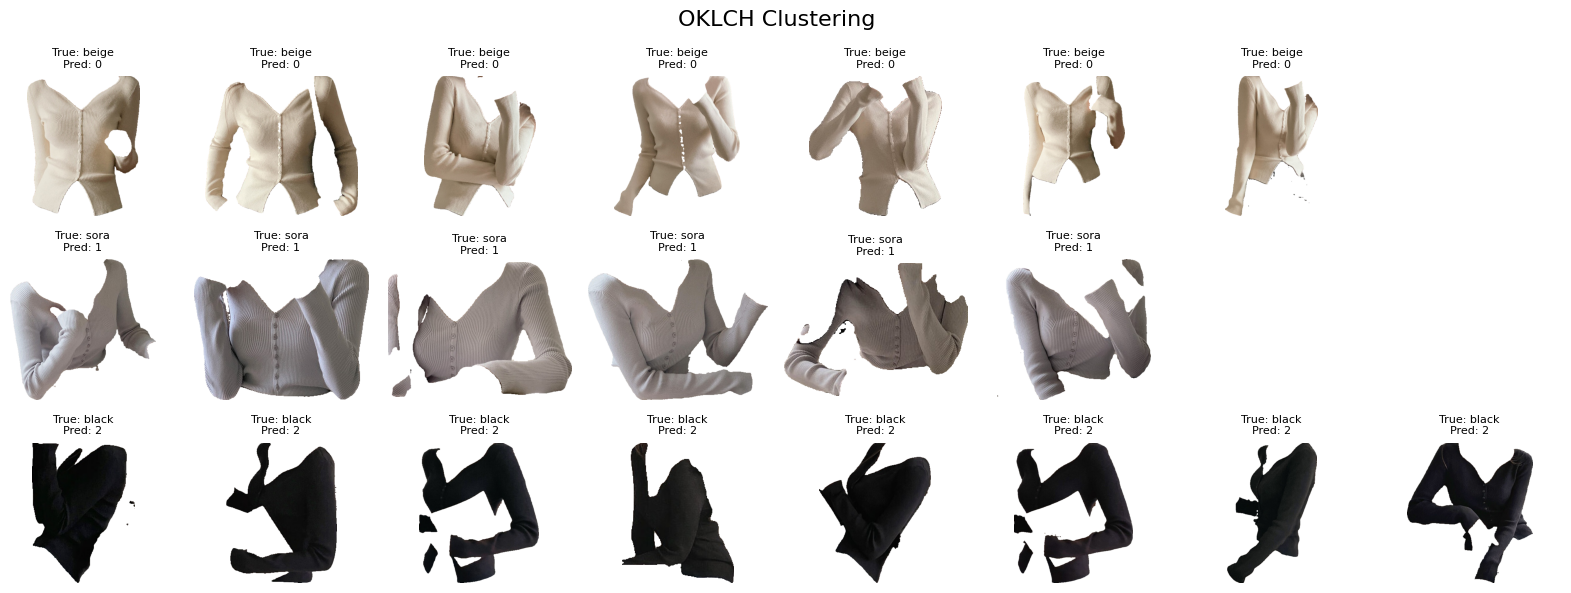

In [ ]:
for space in labels:
    show_clusters(space)

< key function >
- np.bincount(pred).max():	가장 큰 군집의 이미지 개수를 구해 열 개수 결정
- plt.subplots()):	군집마다 한 행씩 배치하는 그래프 격자 생성
- np.where(pred == c)[0]):	군집 c에 속하는 이미지들의 인덱스 추출
- enumerate()):	군집 내 각 이미지에 열 위치 번호 부여
- ~masks[idx]):	마스크를 반전하여 배경 픽셀 선택
- img[~masks[idx]] = 255):	배경 픽셀을 흰색으로 변경
- axes[c, j].imshow(img)):	해당 군집의 이미지 출력
- ax.axis('off')):	그래프 축 숨기기
- fig.suptitle()):	전체 그래프 제목 설정
- set_title()):	개별 이미지 제목 설정
- plt.tight_layout()):	그래프 요소가 겹치지 않도록 간격 자동 조정